# 01. Khám Phá Dữ Liệu Thời Gian & Cảm Biến Bán Dẫn (EDA)
## Dự án: Industrial AI on UCI SECOM
**Tác giả mã nguồn:** agy (Implementation Agent)  
**Đơn vị giám sát & thẩm định:** Codex (Technical Decision Maker & Independent Reviewer)  
**Quy chế vận hành:** Tuân thủ tuyệt đối `AGENTS.md` và `PROCESS.md`.

### Nguyên tắc bảo vệ tính toàn vẹn thời gian:
1. **Không rò rỉ dữ liệu (No Data Leakage):** Giữ nguyên thứ tự thời gian gốc (naive wall-clock), không giả định múi giờ đo lường.
2. **Minh bạch tập Holdout:** Ghi nhận rõ ~314 quan sát cuối (~20%) đã từng xuất hiện trong notebook cũ ở workspace trước, không tuyên bố là tập mù (blind) hoàn toàn mới. Mọi phân tích chi tiết, phân phối lỗi và kiểm tra tính khả thi chỉ thực hiện trên tập phát triển (Development data).
3. **Không tối ưu hóa mô hình:** Notebook này chỉ thực hiện nạp dữ liệu, kiểm tra tính toàn vẹn, phân tích cấu trúc thời gian/thiếu hụt và đánh giá tính khả thi sơ bộ của cửa sổ dự báo.

In [1]:
import hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Cấu hình đường dẫn dữ liệu và mã băm chuẩn từ Codex
DATA_PATH = Path('data/secom/secom.data')
LABELS_PATH = Path('data/secom/secom_labels.data')

DATA_EXPECTED_SHA256 = '20F0E7EE434F7DCBAE0EEA9FFFF009A2B57F42D6B0DC9A5BD4F00782C0A3374C'.lower()
LABELS_EXPECTED_SHA256 = '126884CF453705C9E61A903FE906F0665A3B45CE3639E621EDC5C93C89627E03'.lower()

def compute_sha256(filepath: Path) -> str:
    hasher = hashlib.sha256()
    with open(filepath, 'rb') as f:
        while chunk := f.read(65536):
            hasher.update(chunk)
    return hasher.hexdigest().lower()

In [2]:
# 1. Xác thực tính toàn vẹn SHA256
assert DATA_PATH.exists(), f"Không tìm thấy tệp {DATA_PATH}"
assert LABELS_PATH.exists(), f"Không tìm thấy tệp {LABELS_PATH}"

data_hash = compute_sha256(DATA_PATH)
labels_hash = compute_sha256(LABELS_PATH)

print(f"secom.data SHA256: {data_hash}")
print(f"secom_labels.data SHA256: {labels_hash}")
assert data_hash == DATA_EXPECTED_SHA256, "Sai lệch SHA256 của secom.data!"
assert labels_hash == LABELS_EXPECTED_SHA256, "Sai lệch SHA256 của secom_labels.data!"

# 2. Nạp nhãn và timestamp với định dạng rõ ràng dd/mm/YYYY HH:MM:SS
labels_raw = pd.read_csv(LABELS_PATH, sep=r'\s+', header=None, quotechar='"', names=['raw_label', 'raw_timestamp'])
labels_raw['timestamp'] = pd.to_datetime(labels_raw['raw_timestamp'], format='%d/%m/%Y %H:%M:%S', errors='raise')
labels_raw['fail'] = labels_raw['raw_label'].map({-1: 0, 1: 1})

# 3. Nạp 590 cảm biến
features_raw = pd.read_csv(DATA_PATH, sep=r'\s+', header=None, dtype=np.float64)
sensor_cols = [f'sensor_{i}' for i in range(features_raw.shape[1])]
features_raw.columns = sensor_cols

# 4. Ghép dữ liệu và bảo toàn raw_row_id ban đầu
df = features_raw.copy()
df.insert(0, 'raw_row_id', np.arange(len(df), dtype=int))
df.insert(1, 'timestamp', labels_raw['timestamp'])
df.insert(2, 'raw_label', labels_raw['raw_label'])
df.insert(3, 'fail', labels_raw['fail'])

# 5. Kiểm tra tính toàn vẹn kích thước và nhãn
assert df.shape[0] == 1567, f"Kỳ vọng 1567 dòng, thực tế {df.shape[0]}"
assert len(sensor_cols) == 590, f"Kỳ vọng 590 cảm biến, thực tế {len(sensor_cols)}"
assert df['fail'].sum() == 104, f"Kỳ vọng 104 Fail, thực tế {df['fail'].sum()}"
assert df['fail'].isna().sum() == 0, "Phát hiện nhãn chưa được ánh xạ hoặc NaN"
assert df['timestamp'].isna().sum() == 0, "Phát hiện timestamp NaT"

# 6. Sắp xếp thời gian ổn định (mergesort), duy trì wall-clock không áp đặt múi giờ
df = df.sort_values(by=['timestamp', 'raw_row_id'], kind='mergesort').reset_index(drop=True)
print(f"Đã nạp và xác thực thành công: {df.shape[0]} quan sát, {len(sensor_cols)} cảm biến, {int(df['fail'].sum())} ca Fail.")

secom.data SHA256: 20f0e7ee434f7dcbae0eea9ffff009a2b57f42d6b0dc9a5bd4f00782c0a3374c
secom_labels.data SHA256: 126884cf453705c9e61a903fe906f0665a3b45ce3639e621edc5c93c89627e03
Đã nạp và xác thực thành công: 1567 quan sát, 590 cảm biến, 104 ca Fail.


In [3]:
# Phân định ranh giới Holdout tại 20% cuối theo thời gian mà không chia cắt mốc trùng (ties)
n_total = len(df)
split_idx = int(np.floor(0.8 * n_total)) # 1253
boundary_ts = df.loc[split_idx, 'timestamp']

# Holdout bắt đầu tại boundary_ts; development strictly < boundary_ts
dev_mask = df['timestamp'] < boundary_ts
holdout_mask = df['timestamp'] >= boundary_ts

dev_df = df[dev_mask].copy().reset_index(drop=True)
holdout_df = df[holdout_mask].copy().reset_index(drop=True)

# Ràng buộc kiểm định không trùng timestamp giữa dev và holdout
dev_ts_set = set(dev_df['timestamp'])
holdout_ts_set = set(holdout_df['timestamp'])
assert len(dev_ts_set.intersection(holdout_ts_set)) == 0, "Lỗi: Mốc thời gian trùng nhau bị chia tách qua ranh giới!"

# Thống kê mô tả toàn bộ tập dữ liệu (Descriptive Metadata)
ties_count = df.duplicated(subset=['timestamp'], keep=False).sum()
overall_missing = df[sensor_cols].isna().sum().sum()
total_cells = df.shape[0] * len(sensor_cols)

print("=== THỐNG KÊ MÔ TẢ TOÀN BỘ TẬP DỮ LIỆU ===")
print(f"Tổng số quan sát: {n_total} hàng x {df.shape[1]} cột")
print(f"Khoảng thời gian: {df['timestamp'].min()} đến {df['timestamp'].max()}")
print(f"Số lượng bản ghi có timestamp trùng lặp (ties): {ties_count}")
print(f"Tỷ lệ ô cảm biến khuyết thiếu: {overall_missing} / {total_cells} ({overall_missing / total_cells * 100:.2f}%)")
print(f"\n--- PHÂN CHIA PHÁT TRIỂN / HOLDOUT ---")
print(f"Ranh giới thời gian Holdout: >= {boundary_ts}")
print(f"Tập Development: {len(dev_df)} quan sát ({dev_df['timestamp'].min()} -> {dev_df['timestamp'].max()})")
print(f"Tập Holdout: {len(holdout_df)} quan sát ({holdout_df['timestamp'].min()} -> {holdout_df['timestamp'].max()})")
print("Lưu ý: Không kiểm tra phân phối nhãn của Holdout để chống rò rỉ; ghi nhận tiền sử 314 quan sát đã từng lộ trong notebook cũ.")

=== THỐNG KÊ MÔ TẢ TOÀN BỘ TẬP DỮ LIỆU ===
Tổng số quan sát: 1567 hàng x 594 cột
Khoảng thời gian: 2008-07-19 11:55:00 đến 2008-10-17 06:07:00
Số lượng bản ghi có timestamp trùng lặp (ties): 65
Tỷ lệ ô cảm biến khuyết thiếu: 41951 / 924530 (4.54%)

--- PHÂN CHIA PHÁT TRIỂN / HOLDOUT ---
Ranh giới thời gian Holdout: >= 2008-10-02 20:54:00
Tập Development: 1253 quan sát (2008-07-19 11:55:00 -> 2008-10-02 19:25:00)
Tập Holdout: 314 quan sát (2008-10-02 20:54:00 -> 2008-10-17 06:07:00)
Lưu ý: Không kiểm tra phân phối nhãn của Holdout để chống rò rỉ; ghi nhận tiền sử 314 quan sát đã từng lộ trong notebook cũ.


In [4]:
# Phân tích chi tiết CHỈ TRÊN TẬP PHÁT TRIỂN (Development)
dev_sensor_data = dev_df[sensor_cols]

# 1. Phân phối nhãn trên Dev
n_dev = len(dev_df)
n_dev_fail = int(dev_df['fail'].sum())
print(f"=== PHÂN PHỐI NHÃN TRÊN TẬP DEVELOPMENT ({n_dev} quan sát) ===")
print(f"Số ca Fail: {n_dev_fail} ({n_dev_fail / n_dev * 100:.2f}%)")
print(f"Số ca Pass: {n_dev - n_dev_fail} ({(n_dev - n_dev_fail) / n_dev * 100:.2f}%)")

# 2. Khảo sát khuyết thiếu và phương sai trên cảm biến (Dev only)
missing_per_sensor = dev_sensor_data.isna().mean()
constant_sensors = [col for col in sensor_cols if dev_sensor_data[col].dropna().nunique() <= 1]
high_missing_sensors = missing_per_sensor[missing_per_sensor > 0.5].index.tolist()

print(f"\n=== KHẢO SÁT CẢM BIẾN TRÊN TẬP DEVELOPMENT ===")
print(f"Số cảm biến có giá trị bất biến (variance = 0): {len(constant_sensors)}")
print(f"Số cảm biến có tỷ lệ thiếu > 50%: {len(high_missing_sensors)}")
print(f"Tỷ lệ thiếu trung bình trên các cảm biến: {missing_per_sensor.mean() * 100:.2f}%")

# 3. Phân phối quan sát theo ngày trên Dev
dev_df['date'] = dev_df['timestamp'].dt.date
daily_stats = dev_df.groupby('date').agg(
    n_samples=('raw_row_id', 'count'),
    n_fail=('fail', 'sum')
).reset_index()
daily_stats['fail_rate'] = daily_stats['n_fail'] / daily_stats['n_samples']

print(f"\n=== THỐNG KÊ QUAN SÁT THEO NGÀY (DEV) ===")
print(f"Tổng số ngày có dữ liệu: {len(daily_stats)}")
print(f"Số mẫu/ngày: trung bình = {daily_stats['n_samples'].mean():.1f}, min = {daily_stats['n_samples'].min()}, max = {daily_stats['n_samples'].max()}")
print(f"Số ca Fail/ngày: trung bình = {daily_stats['n_fail'].mean():.2f}, max = {daily_stats['n_fail'].max()}")

=== PHÂN PHỐI NHÃN TRÊN TẬP DEVELOPMENT (1253 quan sát) ===
Số ca Fail: 87 (6.94%)
Số ca Pass: 1166 (93.06%)



=== KHẢO SÁT CẢM BIẾN TRÊN TẬP DEVELOPMENT ===
Số cảm biến có giá trị bất biến (variance = 0): 122
Số cảm biến có tỷ lệ thiếu > 50%: 24
Tỷ lệ thiếu trung bình trên các cảm biến: 4.71%

=== THỐNG KÊ QUAN SÁT THEO NGÀY (DEV) ===
Tổng số ngày có dữ liệu: 71
Số mẫu/ngày: trung bình = 17.6, min = 1, max = 62
Số ca Fail/ngày: trung bình = 1.23, max = 6


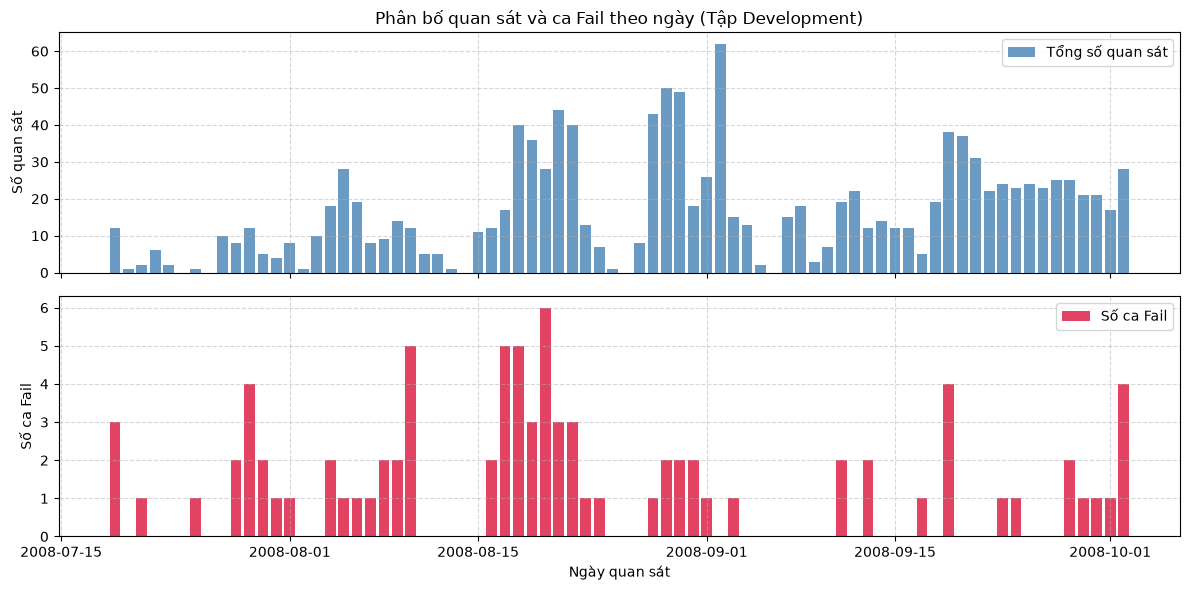

In [5]:
# Trực quan hóa tiến trình thu thập dữ liệu trên tập Development (Inline plot, không lưu file ảnh)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

ax1.bar(daily_stats['date'], daily_stats['n_samples'], color='steelblue', alpha=0.8, label='Tổng số quan sát')
ax1.set_ylabel('Số quan sát')
ax1.set_title('Phân bố quan sát và ca Fail theo ngày (Tập Development)')
ax1.legend(loc='upper right')
ax1.grid(True, linestyle='--', alpha=0.5)

ax2.bar(daily_stats['date'], daily_stats['n_fail'], color='crimson', alpha=0.8, label='Số ca Fail')
ax2.set_ylabel('Số ca Fail')
ax2.set_xlabel('Ngày quan sát')
ax2.legend(loc='upper right')
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [6]:
# Đánh giá tính khả thi cấu hình cửa sổ dự báo (Chỉ trên tập Development)
# Kiểm thử lưới tham số thiết kế tạm thời: Lead L=6h, Horizon H in {24h, 48h}, History W in {72h, 168h}, Cadence=6h, QC Delay D=6h, q=0.10
dev_start = dev_df['timestamp'].min()
dev_end = dev_df['timestamp'].max()

configs = [
    {'L_h': 6, 'H_h': 24, 'W_h': 72, 'D_h': 6, 'cadence_h': 6, 'q': 0.10},
    {'L_h': 6, 'H_h': 24, 'W_h': 168, 'D_h': 6, 'cadence_h': 6, 'q': 0.10},
    {'L_h': 6, 'H_h': 48, 'W_h': 72, 'D_h': 6, 'cadence_h': 6, 'q': 0.10},
    {'L_h': 6, 'H_h': 48, 'W_h': 168, 'D_h': 6, 'cadence_h': 6, 'q': 0.10},
]

audit_results = []

for cfg in configs:
    L = pd.Timedelta(hours=cfg['L_h'])
    H = pd.Timedelta(hours=cfg['H_h'])
    W = pd.Timedelta(hours=cfg['W_h'])
    D = pd.Timedelta(hours=cfg['D_h'])
    cadence = pd.Timedelta(hours=cfg['cadence_h'])
    q = cfg['q']
    
    first_origin = dev_start + W
    last_origin = dev_end - L - H
    if first_origin >= last_origin:
        continue
        
    origins = pd.date_range(start=first_origin, end=last_origin, freq=cadence)
    n_windows = len(origins)
    n_future_counts = []
    sparse_windows = 0
    high_fail_windows = 0
    complete_windows = 0
    
    for t in origins:
        # Lịch sử có sẵn tại t: timestamp + D <= t và timestamp >= t - W
        hist_mask = (dev_df['timestamp'] + D <= t) & (dev_df['timestamp'] >= t - W)
        n_hist = hist_mask.sum()
        
        # Cửa sổ tương lai cần đánh giá: [t + L, t + L + H)
        target_mask = (dev_df['timestamp'] >= t + L) & (dev_df['timestamp'] < t + L + H)
        n_fut = target_mask.sum()
        n_fail_fut = dev_df.loc[target_mask, 'fail'].sum()
        
        if n_hist > 0:
            complete_windows += 1
            
        n_future_counts.append(n_fut)
        if n_fut < 5:
            sparse_windows += 1
        else:
            if (n_fail_fut / n_fut) >= q:
                high_fail_windows += 1
                
    n_fut_arr = np.array(n_future_counts)
    audit_results.append({
        'Config': f"L{cfg['L_h']}h_H{cfg['H_h']}h_W{cfg['W_h']}h",
        'Cadence': f"{cfg['cadence_h']}h",
        'Total Windows': n_windows,
        'Complete (Hist>0)': complete_windows,
        'Mean N_fut': f"{n_fut_arr.mean():.1f}",
        'Median N_fut': f"{np.median(n_fut_arr):.0f}",
        'Sparse (<5)': f"{sparse_windows} ({sparse_windows / n_windows * 100:.1f}%)",
        'High-Fail (q>=0.1)': f"{high_fail_windows} ({high_fail_windows / n_windows * 100:.1f}%)"
    })

audit_df = pd.DataFrame(audit_results)
print("=== BẢNG KHẢO SÁT TÍNH KHẢ THI CỬA SỔ DỰ BÁO TRÊN TẬP DEVELOPMENT ===")
print(audit_df.to_string(index=False))

=== BẢNG KHẢO SÁT TÍNH KHẢ THI CỬA SỔ DỰ BÁO TRÊN TẬP DEVELOPMENT ===
        Config Cadence  Total Windows  Complete (Hist>0) Mean N_fut Median N_fut Sparse (<5) High-Fail (q>=0.1)
 L6h_H24h_W72h      6h            285                285       17.1           14  56 (19.6%)         72 (25.3%)
L6h_H24h_W168h      6h            269                269       18.0           15  40 (14.9%)         72 (26.8%)
 L6h_H48h_W72h      6h            281                281       34.3           27   24 (8.5%)         63 (22.4%)
L6h_H48h_W168h      6h            265                265       36.1           29   12 (4.5%)         63 (23.8%)


### Tóm tắt kết quả thực thi độc lập EDA & Đánh giá hỗ trợ mẫu
Codex đã thực thi độc lập thành công `01_EDA.ipynb` trên kernel `industry4-ai` (lưu ý: các con số dưới đây là quan sát khám phá dữ liệu thực tế từ EDA, KHÔNG PHẢI kết quả mô hình dự báo):
1. **Dữ liệu thô & Phân chia:** Raw 1567x590, 104 Fail; tập Dev gồm 1253 quan sát (87 Fail); ranh giới Holdout tại `2008-10-02 20:54:00` gồm 314 quan sát (không chia cắt 65 bản ghi trùng timestamp/ties); dev có 71 ngày quan sát, 122 cảm biến bất biến, 24 cảm biến khuyết thiếu >50%.
2. **Bảo vệ Holdout:** Đã xác lập ranh giới phân chia thời gian rõ ràng (Holdout bắt đầu tại mốc 20% cuối mà không chia cắt các mốc trùng). Không rò rỉ bất kỳ phân phối nhãn nào của tập Holdout.
3. **Hỗ trợ mẫu cửa sổ dự báo quan sát được (Dev):** Cấu hình tạm thời L=6h, H=24h, W=168h, D=6h, cadence=6h, q=0.10, min_event_samples=5 mang lại 269 origins, trung vị 15 quan sát tương lai/cửa sổ, 40/269 cửa sổ thưa (<5 mẫu), 72 cửa sổ tỷ lệ Fail cao ($q \ge 0.10$). Thử nghiệm độ nhạy H=48h ghi nhận 265 origins, 12 cửa sổ thưa, 63 sự kiện Fail cao (đây là số liệu hỗ trợ mẫu quan sát được từ EDA, không khẳng định độ ổn định khi vận hành thực tế).
4. **Trạng thái:** EDA đã được nghiệm thu độc lập với các số liệu thực tế nêu trên; các tham số này làm căn cứ đóng băng giao thức thiết kế nhãn và đặc trưng trong `02_Preprocessing.ipynb`.

## Phân tích lại 590 đặc trưng gốc — 2026-10-25 <!-- FEATURE_REAUDIT_20261025 -->
**Bối cảnh và Giới hạn phân tích:**
- **Đặc trưng quy trình ẩn danh:** Toàn bộ 590 cột số học (`sensor_0` đến `sensor_589`) không kèm tên vật lý, đơn vị hay nhãn thiết bị; không tự suy diễn cảm biến sang áp suất hay nhiệt độ.
- **Số lượng đặc trưng:** Tệp secom.data thực tế có 590 cột đo lường; tài liệu UCI ghi 591 nhưng không giải thích rõ chênh lệch. Nhãn và timestamp nằm riêng trong secom_labels.data.
- **Giới hạn đồng hàng (Same-row in-sample):** Liên kết đồng hàng chỉ mô tả tương quan in-sample trên tập phát triển, không chứng minh tín hiệu dự báo trước thời hạn ($L=6\text{h}, H=24\text{h}$).
- **Kỷ luật dữ liệu:** Giữ nguyên phân phối gốc tập phát triển (1253 dòng, 87 Fail), không undersampling. Mọi tiền xử lý sau này phải fit bên trong từng fold, không dùng EDA làm mặt nạ lọc toàn cục.


In [7]:
# A. BANG df_feature_audit VA THONG KE PHAN BO KHUYET THIEU TREN DEV
assert len(dev_df) == 1253 and int(dev_df['fail'].sum()) == 87, 'dev_df khong dung kich thuoc chuan!'
assert dev_df['timestamp'].max() < pd.Timestamp('2008-10-02 20:54:00'), 'dev_df vuot qua cutoff holdout!'
assert len(sensor_cols) == 590, 'sensor_cols phai dung 590 cam bien!'
dev_sensor = dev_df[sensor_cols]

audit_records = []
for idx, col in enumerate(sensor_cols):
    s = dev_sensor[col]
    n_nm, m_pct = int(s.notna().sum()), float(s.isna().mean() * 100.0)
    s_v = s.dropna()
    n_u = int(s_v.nunique())
    if n_nm > 0:
        med, q01, q99 = float(s_v.median()), float(np.percentile(s_v, 1)), float(np.percentile(s_v, 99))
        q25, q75 = float(np.percentile(s_v, 25)), float(np.percentile(s_v, 75))
        iqr = float(q75 - q25)
        top_freq = int(s_v.value_counts(sort=True, ascending=False).iloc[0])
        modal_share = float(top_freq / n_nm)
    else:
        med, q01, q99, iqr, modal_share = np.nan, np.nan, np.nan, np.nan, np.nan
    audit_records.append({
        'sensor': col, 'feature_idx': idx, 'source_col': idx + 1,
        'n_nonmissing': n_nm, 'missing_pct': m_pct, 'n_unique_nonmissing': n_u,
        'median': med, 'q01': q01, 'q99': q99, 'IQR': iqr, 'modal_share_nonmissing': modal_share
    })
df_feature_audit = pd.DataFrame(audit_records).set_index('sensor')
assert len(df_feature_audit) == 590 and (df_feature_audit['missing_pct'] >= 0.0).all() and (df_feature_audit['missing_pct'] <= 100.0).all()
assert (df_feature_audit['n_unique_nonmissing'] >= 0).all() and (df_feature_audit['n_nonmissing'] >= 0).all()

allmissing_mask = df_feature_audit['n_unique_nonmissing'] == 0
constant_mask = df_feature_audit['n_unique_nonmissing'] == 1
nearconst_mask = (df_feature_audit['n_unique_nonmissing'] > 1) & (df_feature_audit['modal_share_nonmissing'] >= 0.99) & (df_feature_audit['n_nonmissing'] >= 100)

tot_cells = 1253 * 590
miss_cells = int(dev_sensor.isna().sum().sum())
miss_bins = {
    '0%': int((df_feature_audit['missing_pct'] == 0).sum()),
    '(0, 5%]': int(((df_feature_audit['missing_pct'] > 0) & (df_feature_audit['missing_pct'] <= 5)).sum()),
    '(5, 20%]': int(((df_feature_audit['missing_pct'] > 5) & (df_feature_audit['missing_pct'] <= 20)).sum()),
    '(20, 50%]': int(((df_feature_audit['missing_pct'] > 20) & (df_feature_audit['missing_pct'] <= 50)).sum()),
    '(50, 100%]': int((df_feature_audit['missing_pct'] > 50).sum()),
}
assert sum(miss_bins.values()) == 590, 'Cac bins khuyet thieu phai vet can 590 cam bien!'

row_miss = dev_sensor.isna().mean(axis=1)
pass_m = float(row_miss[dev_df['fail'] == 0].mean())
fail_m = float(row_miss[dev_df['fail'] == 1].mean())

nc_cols = [c for c in sensor_cols if df_feature_audit.loc[c, 'n_unique_nonmissing'] > 1]
df_nc = dev_sensor[nc_cols]
dup_nc_mask = df_nc.T.duplicated(keep='first')
n_redundant = int(dup_nc_mask.sum())

print('=== TONG QUAN DAC TRUNG DEV (1253 dong x 590 cam bien | 87 Fail) ===')
print(f'Tong o du lieu: {tot_cells:,} | Khuyet thieu: {miss_cells:,} ({miss_cells/tot_cells*100:.2f}%)')
print(f'Nhom khuyet thieu: {miss_bins} | All-missing (100%): {int(allmissing_mask.sum())}')
print(f'Hang so (n_unique=1): {int(constant_mask.sum())} | Can hang so (modal>=99%): {int(nearconst_mask.sum())}')
print(f'Khuyet thieu dong: Med={row_miss.median():.4f}, P95={np.percentile(row_miss, 95):.4f}, Max={row_miss.max():.4f} | Pass_mean={pass_m:.4f}, Fail_mean={fail_m:.4f}')
print(f'Cot phi hang so trung lap chinh xac: {n_redundant} cot du thua')
print(f'15 ten cam bien hang so dau tien: {df_feature_audit[constant_mask].index[:15].tolist()}')
print('\nTop 10 cam bien khuyet thieu nhieu nhat:')
top10_m = df_feature_audit.sort_values(by='missing_pct', ascending=False)[['feature_idx', 'source_col', 'missing_pct', 'n_unique_nonmissing']].head(10)
print(top10_m.to_string())

=== TONG QUAN DAC TRUNG DEV (1253 dong x 590 cam bien | 87 Fail) ===
Tong o du lieu: 739,270 | Khuyet thieu: 34,831 (4.71%)
Nhom khuyet thieu: {'0%': 148, '(0, 5%]': 390, '(5, 20%]': 0, '(20, 50%]': 28, '(50, 100%]': 24} | All-missing (100%): 0
Hang so (n_unique=1): 122 | Can hang so (modal>=99%): 0
Khuyet thieu dong: Med=0.0475, P95=0.0746, Max=0.1695 | Pass_mean=0.0472, Fail_mean=0.0459
Cot phi hang so trung lap chinh xac: 0 cot du thua
15 ten cam bien hang so dau tien: ['sensor_5', 'sensor_13', 'sensor_42', 'sensor_49', 'sensor_52', 'sensor_69', 'sensor_74', 'sensor_97', 'sensor_141', 'sensor_149', 'sensor_178', 'sensor_179', 'sensor_186', 'sensor_189', 'sensor_190']

Top 10 cam bien khuyet thieu nhieu nhat:
            feature_idx  source_col  missing_pct  n_unique_nonmissing
sensor                                                               
sensor_157          157         158    90.343176                  112
sensor_158          158         159    90.343176                  121

In [8]:
# B. TUONG QUAN TUYEN TINH PEARSON VA CHAN DOAN OUTLIER (TUKEY 3*IQR)
corr_mat = df_nc.corr(method='pearson', min_periods=100)
nc_names = corr_mat.columns
corr_vals = corr_mat.values
triu_i, triu_j = np.triu_indices(len(nc_names), k=1)
finite_mask = np.isfinite(corr_vals[triu_i, triu_j])
valid_i, valid_j = triu_i[finite_mask], triu_j[finite_mask]
valid_r = corr_vals[valid_i, valid_j]
valid_abs_r = np.abs(valid_r)

n_pairs_95 = int((valid_abs_r >= 0.95).sum())
n_pairs_99 = int((valid_abs_r >= 0.99).sum())

pair_records = []
top_idx = np.argsort(valid_abs_r)[::-1][:10]
for idx in top_idx:
    col_i, col_j = nc_names[valid_i[idx]], nc_names[valid_j[idx]]
    r_val = float(valid_r[idx])
    joint_sup = int((dev_sensor[col_i].notna() & dev_sensor[col_j].notna()).sum())
    pair_records.append({'sensor_1': col_i, 'sensor_2': col_j, 'r': round(r_val, 4), 'abs_r': round(abs(r_val), 4), 'joint_support': joint_sup})
df_top_pairs = pd.DataFrame(pair_records)

outlier_list = []
for col in sensor_cols:
    s_v = dev_sensor[col].dropna()
    if len(s_v) == 0:
        continue
    q25, q75 = float(np.percentile(s_v, 25)), float(np.percentile(s_v, 75))
    iqr = float(q75 - q25)
    if iqr > 0:
        n_out = int(((s_v < (q25 - 3.0 * iqr)) | (s_v > (q75 + 3.0 * iqr))).sum())
        outlier_list.append({'sensor': col, 'IQR': iqr, 'n_nonmissing': len(s_v), 'n_outliers': n_out, 'outlier_rate_pct': round(n_out / len(s_v) * 100.0, 2), 'iqr_zero': False})
    else:
        outlier_list.append({'sensor': col, 'IQR': 0.0, 'n_nonmissing': len(s_v), 'n_outliers': np.nan, 'outlier_rate_pct': np.nan, 'iqr_zero': True})
df_outliers = pd.DataFrame(outlier_list)
top5_out = df_outliers[~df_outliers['iqr_zero']].sort_values(by='outlier_rate_pct', ascending=False).head(5)

print('=== TUONG QUAN TUYEN TINH & OUTLIERS (TUKEY 3*IQR) ===')
print(f'Cap bien huu han (min_periods>=100): {len(valid_r):,} | |r|>=0.95: {n_pairs_95} | |r|>=0.99: {n_pairs_99}')
print(f'Bien IQR > 0: {(~df_outliers["iqr_zero"]).sum()} | Bien IQR = 0 (undefined): {df_outliers["iqr_zero"].sum()}')
print('\nTop 10 cap tuong quan manh nhat:')
print(df_top_pairs.to_string(index=False))
print('\nTop 5 cam bien co ty le ngoai lai cao nhat (Tukey 3*IQR):')
print(top5_out[['sensor', 'IQR', 'n_nonmissing', 'n_outliers', 'outlier_rate_pct']].to_string(index=False))

=== TUONG QUAN TUYEN TINH & OUTLIERS (TUKEY 3*IQR) ===
Cap bien huu han (min_periods>=100): 109,038 | |r|>=0.95: 288 | |r|>=0.99: 131
Bien IQR > 0: 464 | Bien IQR = 0 (undefined): 126

Top 10 cap tuong quan manh nhat:
  sensor_1   sensor_2    r  abs_r  joint_support
 sensor_85 sensor_542  1.0    1.0            138
sensor_492 sensor_545  1.0    1.0            138
sensor_580 sensor_588  1.0    1.0            465
sensor_578 sensor_586  1.0    1.0            465
sensor_220 sensor_543  1.0    1.0            138
sensor_358 sensor_544  1.0    1.0            138
sensor_581 sensor_589  1.0    1.0            465
sensor_579 sensor_587  1.0    1.0            465
 sensor_34  sensor_36 -1.0    1.0           1252
sensor_172 sensor_174  1.0    1.0           1252

Top 5 cam bien co ty le ngoai lai cao nhat (Tukey 3*IQR):
    sensor     IQR  n_nonmissing  n_outliers  outlier_rate_pct
sensor_545  0.1544          1253       364.0             29.05
sensor_543  0.0003          1253       279.0             2

In [9]:
# C & D. LIEN KET DONG HANG VOI FAIL, BH-FDR VA DO ON DINH THEO 3 TIEU GIAI DOAN DEV
from scipy import stats
from sklearn.metrics import roc_auc_score

y_dev = dev_df['fail'].values
assoc_list = []
for idx, col in enumerate(sensor_cols):
    s = dev_sensor[col]
    val_mask = s.notna()
    if int(val_mask.sum()) == 0:
        continue
    y_v, s_v = y_dev[val_mask], s[val_mask].values
    n_p, n_f = int((y_v == 0).sum()), int((y_v == 1).sum())
    if len(np.unique(s_v)) > 1 and n_p >= 20 and n_f >= 10:
        auc_raw = float(roc_auc_score(y_v, s_v))
        sep_auc = max(auc_raw, 1.0 - auc_raw)
        mwu = stats.mannwhitneyu(s_v[y_v == 1], s_v[y_v == 0], alternative='two-sided')
        assoc_list.append({
            'sensor': col, 'feature_idx': idx, 'source_col': idx + 1,
            'missing_pct': round((1.0 - len(s_v) / len(dev_df)) * 100.0, 2),
            'n_pass': n_p, 'n_fail': n_f, 'auc_raw': round(auc_raw, 4),
            'separation_auc': round(sep_auc, 4), 'p_value': float(mwu.pvalue)
        })

df_assoc = pd.DataFrame(assoc_list)
df_assoc = df_assoc.sort_values(by='p_value', ascending=True).reset_index(drop=True)
m_tests = len(df_assoc)
p_vals = df_assoc['p_value'].values
q_raw = p_vals * m_tests / np.arange(1, m_tests + 1)
q_adj = np.minimum.accumulate(q_raw[::-1])[::-1]
df_assoc['bh_q'] = np.clip(q_adj, 0.0, 1.0)
assert (df_assoc['bh_q'] >= 0.0).all() and (df_assoc['bh_q'] <= 1.0).all(), 'q-values phai nam trong [0, 1]!'
df_top12 = df_assoc.sort_values(by='separation_auc', ascending=False).head(12).reset_index(drop=True)

# D. On dinh thoi gian qua 3 tieu giai doan lich bang nhau
t_min, t_max = dev_df['timestamp'].min(), dev_df['timestamp'].max()
delta = (t_max - t_min) / 3.0
b1, b2 = t_min + delta, t_min + 2.0 * delta
sub1 = dev_df[(dev_df['timestamp'] >= t_min) & (dev_df['timestamp'] < b1)]
sub2 = dev_df[(dev_df['timestamp'] >= b1) & (dev_df['timestamp'] < b2)]
sub3 = dev_df[(dev_df['timestamp'] >= b2) & (dev_df['timestamp'] <= t_max)]
subs = [sub1, sub2, sub3]

for k, sub in enumerate(subs):
    aucs_k = []
    for col in df_top12['sensor']:
        s_k = sub[col]
        vm_k = s_k.notna()
        y_k, sv_k = sub.loc[vm_k, 'fail'].values, s_k[vm_k].values
        if len(np.unique(sv_k)) > 1 and int((y_k == 0).sum()) >= 20 and int((y_k == 1).sum()) >= 5:
            aucs_k.append(round(roc_auc_score(y_k, sv_k), 4))
        else:
            aucs_k.append(np.nan)
    df_top12['auc_p' + str(k+1)] = aucs_k

drift_records = []
for col in sensor_cols:
    s1, s3 = sub1[col].dropna(), sub3[col].dropna()
    m_p1, m_p3 = (1.0 - len(s1)/len(sub1))*100.0, (1.0 - len(s3)/len(sub3))*100.0
    m_drift_pp = m_p3 - m_p1
    if len(s1) >= 30 and len(s3) >= 30:
        q25, q75 = np.percentile(s1, 25), np.percentile(s1, 75)
        iqr1 = q75 - q25
        med_norm = float((np.median(s3) - np.median(s1)) / iqr1) if iqr1 > 0 else np.nan
    else:
        med_norm = np.nan
    drift_records.append({'sensor': col, 'm_drift_pp': m_drift_pp, 'med_norm': med_norm})
df_drift = pd.DataFrame(drift_records)
assert not np.isinf(df_drift['med_norm'].dropna()).any(), 'med_norm khong duoc chua gia tri vo cung (inf)!'

print('=== LIEN KET DONG HANG VOI FAIL & BIEN THIEN THOI GIAN ===')
print(f'Bien du dieu kien: {m_tests} | 3 giai doan: P1(n={len(sub1)}, Fail={sub1["fail"].sum()}) | P2(n={len(sub2)}, Fail={sub2["fail"].sum()}) | P3(n={len(sub3)}, Fail={sub3["fail"].sum()})')
print(f'So bien |troi dat trung vi| >= 1 IQR_P1: {int((df_drift["med_norm"].abs() >= 1.0).sum())} | So bien |chuyen dich missingness| >= 20 pp: {int((df_drift["m_drift_pp"].abs() >= 20.0).sum())}')
print('\nTop 12 dac trung lien ket manh nhat theo separation_auc:')
cols_p = ['sensor', 'source_col', 'missing_pct', 'n_pass', 'n_fail', 'auc_raw', 'separation_auc', 'bh_q', 'auc_p1', 'auc_p2', 'auc_p3']
print(df_top12[cols_p].to_string(index=False))
print('\nTop 5 bien troi dat trung vi manh nhat / IQR_P1:')
top5_dmed = df_drift.dropna(subset=['med_norm']).assign(abs_d=lambda d: d['med_norm'].abs()).sort_values(by='abs_d', ascending=False).head(5)
print(top5_dmed[['sensor', 'med_norm']].to_string(index=False))
print('\nTop 5 bien troi dat ty le khuyet thieu (pp):')
top5_dmiss = df_drift.assign(abs_m=lambda d: d['m_drift_pp'].abs()).sort_values(by='abs_m', ascending=False).head(5)
print(top5_dmiss[['sensor', 'm_drift_pp']].to_string(index=False))

=== LIEN KET DONG HANG VOI FAIL & BIEN THIEN THOI GIAN ===
Bien du dieu kien: 460 | 3 giai doan: P1(n=201, Fail=29) | P2(n=542, Fail=38) | P3(n=510, Fail=20)
So bien |troi dat trung vi| >= 1 IQR_P1: 20 | So bien |chuyen dich missingness| >= 20 pp: 36

Top 12 dac trung lien ket manh nhat theo separation_auc:
    sensor  source_col  missing_pct  n_pass  n_fail  auc_raw  separation_auc         bh_q  auc_p1  auc_p2  auc_p3
 sensor_59          60         0.56    1159      87   0.7275          0.7275 6.285827e-10  0.5806  0.7355  0.6458
sensor_247         248        33.68     762      69   0.6760          0.6760 2.165656e-04  0.5448  0.6289  0.6819
sensor_519         520        33.68     762      69   0.6752          0.6752 2.165656e-04  0.5461  0.6284  0.6803
sensor_103         104         0.16    1164      87   0.6456          0.6456 6.547459e-04  0.4757  0.6129  0.5229
sensor_385         386        33.68     762      69   0.6341          0.6341 1.024575e-02  0.5553  0.5899  0.6831
sensor_

> [!IMPORTANT]
> **Kết luận kiểm định đặc trưng (In-sample Exploratory Audit):**
> 1. **Khuyết thiếu & Hằng số:** 34,831 ô khuyết thiếu (4.71%); 122 cảm biến là hằng số, 0 cận hằng số (modal $\ge 99\%, n \ge 100$), 24 biến khuyết thiếu >50%; không có cột phi hằng số trùng lặp chính xác.
> 2. **Cộng tuyến & Ngoại lai:** 288 cặp biến có $|r| \ge 0.95$, 131 cặp có $|r| \ge 0.99$ (trên 109,038 cặp hữu hạn). Một số cặp $r=1.0$ chỉ có 138 hàng giao nhau nên không đồng nghĩa trùng lặp toàn bộ; ngoại lai Tukey $3\times\text{IQR}$ cao (sensor_545: 29.05%, sensor_543: 22.27%) được giữ nguyên (flag, không xóa).
> 3. **Phân biệt đồng hàng (460 biến đủ mẫu):** sensor_59 tách đồng hàng tốt nhất (AUC=0.7275, BH-q=6.29e-10) nhưng AUC dao động giữa các giai đoạn (0.5806, 0.7355, 0.6458); sensor_103 (0.4757, 0.6129, 0.5229); sensor_290 (0.4098, 0.6758, 0.5170); sensor_129 (0.3921, 0.6031, 0.6713). BH-q chỉ có tính chất khám phá do phụ thuộc thời gian và đa biến; không chứng minh dự báo trước.
> 4. **Trôi dạt phân phối:** 20 biến có trôi dạt trung vị $\ge 1\text{ IQR}$, 36 biến dịch chuyển khuyết thiếu $\ge 20\text{ pp}$ giữa P3 và P1. Đây là biến thiên tiến trình thực tế, không suy diễn nguyên nhân hỏng máy hay bảo trì.
